# Actividad 3.1.2 Implementación técnica del proyecto Heart Disease

**Propósito.** Completar el flujo solicitado en la guía: cargar el dataset, explorar clases, preparar datos, comparar modelos, evaluar, generar cinco predicciones y demostrar una automatización por lotes.

**Alcance académico.** La fuente tiene 1.025 filas y 723 duplicados exactos. Se deduplicará antes de la partición para evitar que copias idénticas aparezcan en entrenamiento y prueba; quedan 302 observaciones únicas. Las clases `target=0` y `target=1` se conservan como códigos del archivo. Este ejercicio no es un producto clínico ni permite diagnóstico. Los cinco ejemplos nuevos son sintéticos, no registros de pacientes.

Ejecuta las celdas en orden. En Colab, monta Drive y deja una copia del repositorio (con `data/` y `src/`) bajo `MyDrive/GDPDD`; ajusta `PROJECT_ROOT` si usas otro nombre.

In [1]:
from pathlib import Path
import sys

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/GDPDD')
else:
    PROJECT_ROOT = Path.cwd().resolve()
    if not (PROJECT_ROOT / 'data/raw/heart.csv').exists():
        PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'data/raw/heart.csv').exists():
    raise FileNotFoundError('No se encontró data/raw/heart.csv. Configura PROJECT_ROOT a la carpeta del repositorio.')
sys.path.insert(0, str(PROJECT_ROOT))
try:
    import sklearn
except ImportError:
    %pip install -q -r {PROJECT_ROOT / 'requirements.txt'}
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import xgboost as xgb
from src.modeling import (FEATURES, TARGET, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
                          train_and_evaluate, save_model, predict_batch)
if not xgb.build_info().get('USE_CUDA', False):
    raise RuntimeError('Esta versión de XGBoost no incluye CUDA; no continuar con entrenamiento CPU.')
print('XGBoost:', xgb.__version__, '| CUDA:', xgb.build_info().get('CUDA_VERSION'))
DATA_PATH = PROJECT_ROOT / 'data/raw/heart.csv'
MODEL_PATH = PROJECT_ROOT / 'outputs/models/heart_disease_pipeline.joblib'
OUTPUT_DIR = PROJECT_ROOT / 'outputs/models'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = PROJECT_ROOT / 'outputs/figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR = PROJECT_ROOT / 'outputs/tables'
TABLES_DIR.mkdir(parents=True, exist_ok=True)
print('Proyecto:', PROJECT_ROOT)
print('Dataset:', DATA_PATH)

XGBoost: 3.2.0 | CUDA: [12, 9]
Proyecto: C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1
Dataset: C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\data\raw\heart.csv


## 1. Carga y análisis inicial

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Dimensiones originales: {df.shape[0]} filas × {df.shape[1]} columnas')
print(f'Filas duplicadas exactas: {df.duplicated().sum()} ({df.duplicated().mean():.1%})')
print('Valores nulos:', int(df.isna().sum().sum()))
print('Columnas:', df.columns.tolist())
display(df.head())
display(df.describe().T)

Dimensiones originales: 1025 filas × 14 columnas
Filas duplicadas exactas: 723 (70.5%)
Valores nulos: 0
Columnas: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


## 2. Clases y gráficos representativos

El gráfico describe la frecuencia de target en el archivo original y tras deduplicar, que será la base del modelado.

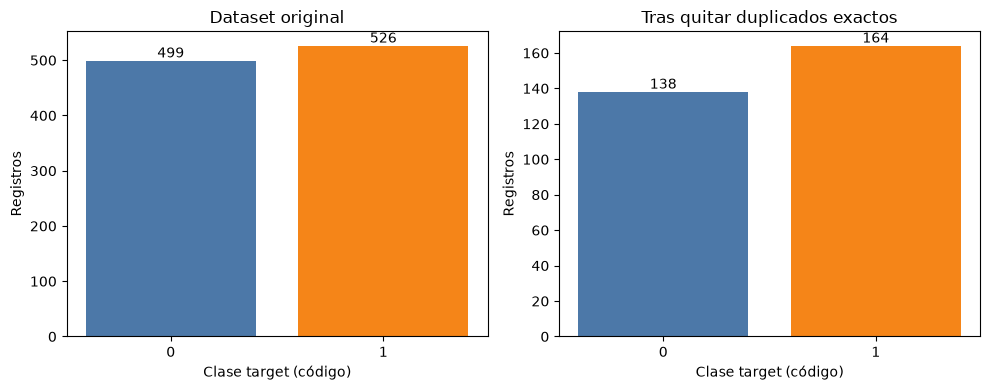

Conteo original:


,registros
target,
0,499
1,526


Conteo deduplicado:


,registros
target,
0,138
1,164


In [3]:
df_unique = df.drop_duplicates().reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, title in [(axes[0], df, 'Dataset original'), (axes[1], df_unique, 'Tras quitar duplicados exactos')]:
    counts = data[TARGET].value_counts().sort_index()
    bars = ax.bar(counts.index.astype(str), counts.values, color=['#4C78A8', '#F58518'])
    ax.set(title=title, xlabel='Clase target (código)', ylabel='Registros')
    ax.bar_label(bars)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'distribucion_clases_antes_despues_deduplicar.png', dpi=180, bbox_inches='tight')
plt.show()
print('Conteo original:')
display(df[TARGET].value_counts().sort_index().rename('registros').to_frame())
print('Conteo deduplicado:')
display(df_unique[TARGET].value_counts().sort_index().rename('registros').to_frame())

## 3. Diagnóstico de correlación, categorías y valores extremos

La matriz de Pearson se limita a variables cuantitativas y `target`; los códigos categóricos no se interpretan como medidas continuas. Para las categorías se calcula una asociación descriptiva entre cada nivel y la clase (correlación de una indicadora binaria con target). Ninguna de estas asociaciones prueba causalidad ni justifica eliminar variables por sí sola.

Los diagramas de caja identifican valores fuera de la regla exploratoria de 1,5×IQR. Esa regla es una señal para revisar, no un criterio automático de error. Se conservan los valores extremos si no hay evidencia de que sean inválidos.

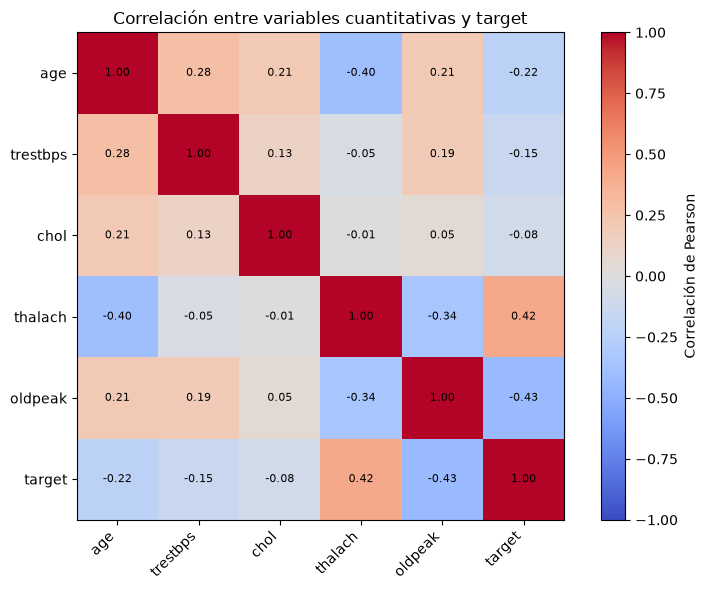

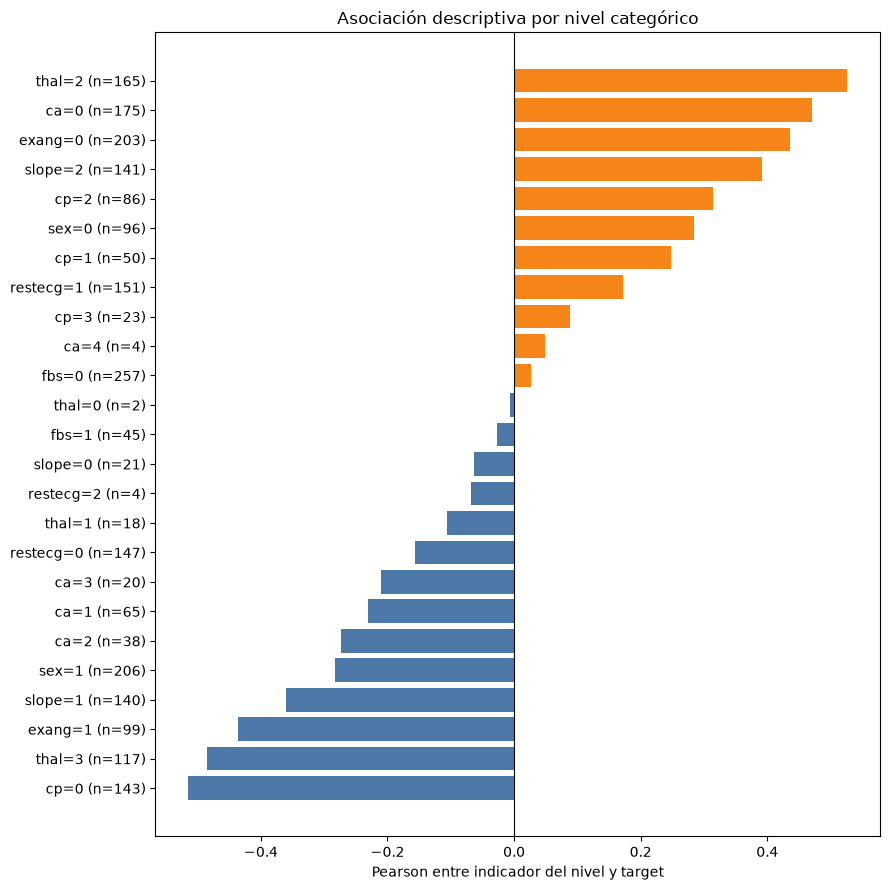

,variable,min,max,limite_inferior_iqr,limite_superior_iqr,conteo_fuera_iqr
0,age,29.0,77.0,28.500,80.500,0
1,trestbps,94.0,200.0,90.000,170.000,9
2,chol,126.0,564.0,115.375,370.375,5
3,thalach,71.0,202.0,84.125,215.125,1
4,oldpeak,0.0,6.2,-2.400,4.000,5


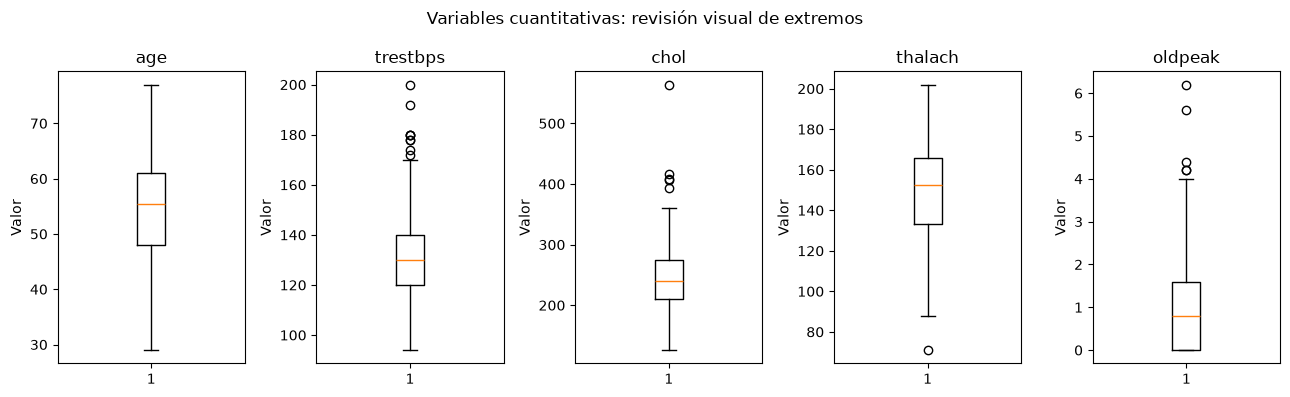

Gráficos y tablas guardados en C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\outputs\figures y C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\outputs\tables


In [4]:
# Correlación de Pearson solo entre variables cuantitativas y target binario.
pearson_corr = df_unique[NUMERIC_FEATURES + [TARGET]].corr(method='pearson')
pearson_corr.to_csv(TABLES_DIR / 'correlacion_pearson_continuas_target.csv')
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(pearson_corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(pearson_corr.columns)), pearson_corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(pearson_corr.index)), pearson_corr.index)
for row in range(len(pearson_corr.index)):
    for col in range(len(pearson_corr.columns)):
        ax.text(col, row, f'{pearson_corr.iloc[row, col]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Correlación de Pearson')
ax.set_title('Correlación entre variables cuantitativas y target')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'matriz_correlacion_continuas_target.png', dpi=180, bbox_inches='tight')
plt.show()

# Asociación univariada de cada nivel categórico con target (indicadora binaria).
association_rows = []
for feature in CATEGORICAL_FEATURES:
    for value in sorted(df_unique[feature].dropna().unique()):
        indicator = df_unique[feature].eq(value).astype(int)
        association_rows.append({
            'nivel': f'{feature}={value} (n={int(indicator.sum())})',
            'variable': feature,
            'categoria': value,
            'n': int(indicator.sum()),
            'correlacion_indicadora_target': indicator.corr(df_unique[TARGET]),
        })
category_association = pd.DataFrame(association_rows).dropna().sort_values(
    'correlacion_indicadora_target'
)
category_association.to_csv(TABLES_DIR / 'asociacion_niveles_categoricos_target.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 9))
colors = ['#4C78A8' if value < 0 else '#F58518' for value in category_association['correlacion_indicadora_target']]
ax.barh(category_association['nivel'], category_association['correlacion_indicadora_target'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Pearson entre indicador del nivel y target', title='Asociación descriptiva por nivel categórico')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'asociacion_niveles_categoricos_target.png', dpi=180, bbox_inches='tight')
plt.show()

# Auditoría IQR sin recortar ni eliminar filas.
rows = []
for feature in NUMERIC_FEATURES:
    q1, q3 = df_unique[feature].quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append({'variable': feature, 'min': df_unique[feature].min(), 'max': df_unique[feature].max(),
                 'limite_inferior_iqr': lower, 'limite_superior_iqr': upper,
                 'conteo_fuera_iqr': int(((df_unique[feature] < lower) | (df_unique[feature] > upper)).sum())})
iqr_audit = pd.DataFrame(rows)
iqr_audit.to_csv(TABLES_DIR / 'auditoria_extremos_iqr.csv', index=False)
display(iqr_audit)
fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(13, 4))
for ax, feature in zip(axes, NUMERIC_FEATURES):
    ax.boxplot(df_unique[feature], showfliers=True)
    ax.set_title(feature)
    ax.set_ylabel('Valor')
fig.suptitle('Variables cuantitativas: revisión visual de extremos')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'diagramas_caja_variables_cuantitativas.png', dpi=180, bbox_inches='tight')
plt.show()
print('Gráficos y tablas guardados en', FIGURES_DIR, 'y', TABLES_DIR)

## 4. Preparación y decisiones de limpieza

La fuente no tiene nulos. Hay 723 duplicados exactos, por eso se quitan antes de la partición; no se recortan por IQR los valores extremos sin evidencia de error. El diccionario del proyecto registra dominios que difieren de UCI en `cp`, `slope`, `ca` y `thal` (incluye `ca=4`); se preservan los valores observados y no se inventan recodificaciones. Al no conocerse la semántica exacta de esta copia, esas variables discretas se tratan como categóricas nominales mediante one-hot, en vez de imponer distancias numéricas entre códigos.

Para la regresión logística, las variables cuantitativas se escalan con `RobustScaler` y las categóricas se codifican dentro del pipeline. XGBoost recibe las cuantitativas sin escalar (los árboles parten por umbrales) y las categóricas one-hot. Todo preprocesamiento se aprende dentro de cada fold para evitar fuga. No se eliminan predictores por correlación: la matriz es exploratoria y no muestra redundancia suficiente para justificar perder señales.

In [5]:
assert set(FEATURES + [TARGET]) == set(df.columns), 'El esquema del dataset cambió.'
assert not df[FEATURES + [TARGET]].isna().any().any(), 'Hay nulos que requieren tratamiento documentado.'
print('Variable dependiente:', TARGET)
print('Variables independientes:', FEATURES)
print(f'Registros para modelado: {len(df_unique)}; descartados por duplicado exacto: {len(df)-len(df_unique)}')
print('Clases disponibles:', sorted(df_unique[TARGET].unique().tolist()))
feature_label_groups = df.groupby(FEATURES, dropna=False)[TARGET].nunique()
label_conflicts = int((feature_label_groups > 1).sum())
print('Combinaciones predictoras repetidas:', len(df) - len(feature_label_groups))
print('Combinaciones predictoras con target contradictorio:', label_conflicts)
assert label_conflicts == 0, 'Revisar filas idénticas en predictores con etiquetas distintas.'

Variable dependiente: target
Variables independientes: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Registros para modelado: 302; descartados por duplicado exacto: 723
Clases disponibles: [0, 1]
Combinaciones predictoras repetidas: 723
Combinaciones predictoras con target contradictorio: 0


## 5. Partición de entrenamiento y prueba

Se usa una partición estratificada 75/25 con semilla fija. El escalado forma parte del pipeline y se ajusta sólo dentro de cada partición de entrenamiento.

In [6]:
result = train_and_evaluate(df)
print('Train:', result['X_train'].shape, '| Test:', result['X_test'].shape)
print('Target train:', result['y_train'].value_counts().sort_index().to_dict())
print('Target test:', result['y_test'].value_counts().sort_index().to_dict())

C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\.venv\Lib\site-packages\xgboost\core.py:751: UserWarning: [21:21:26] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Train: (226, 13) | Test: (76, 13)
Target train: {0: 103, 1: 123}
Target test: {0: 35, 1: 41}


## 6. Entrenamiento, selección e ingeniería de variables

Se comparan el baseline ordinal y pipelines one-hot; la regresión logística con `RobustScaler` sirve como referencia CPU. Se añaden dos experimentos con complejidad limitada: (1) XGBoost con la interacción `oldpeak × exang`; (2) regresión logística con bases spline cuadráticas de tres nudos para las cinco variables continuas. Son transformaciones de representación, no causas clínicas ni variables nuevas medidas. Se puntúan con los mismos cinco folds estratificados dentro de train. Los candidatos experimentales no participan en la selección final; el conjunto test sigue reservado. Si CUDA no está disponible, XGBoost falla en vez de cambiar silenciosamente a CPU.

,modelo,dispositivo,preparación,roc_auc_cv_promedio,roc_auc_cv_desv
0,"Regresión logística (RobustScaler + one-hot, CPU)",CPU,One-hot + RobustScaler numérico,0.919,0.052
1,XGBoost CUDA (baseline ordinal previo),CUDA GPU,Códigos originales como ordinales (pipeline previo),0.917,0.062
2,XGBoost CUDA (one-hot somero),CUDA GPU,Categóricas one-hot,0.914,0.055
3,XGBoost CUDA (one-hot regularizado),CUDA GPU,Categóricas one-hot,0.913,0.061
4,XGBoost CUDA (experimental: one-hot + oldpeak×exang),CUDA GPU,One-hot + interacción oldpeak×exang (experimental),0.912,0.056
5,"Regresión logística (experimental: splines + one-hot, CPU)",CPU,One-hot + splines cuadráticos con 3 nudos (experimental),0.904,0.043


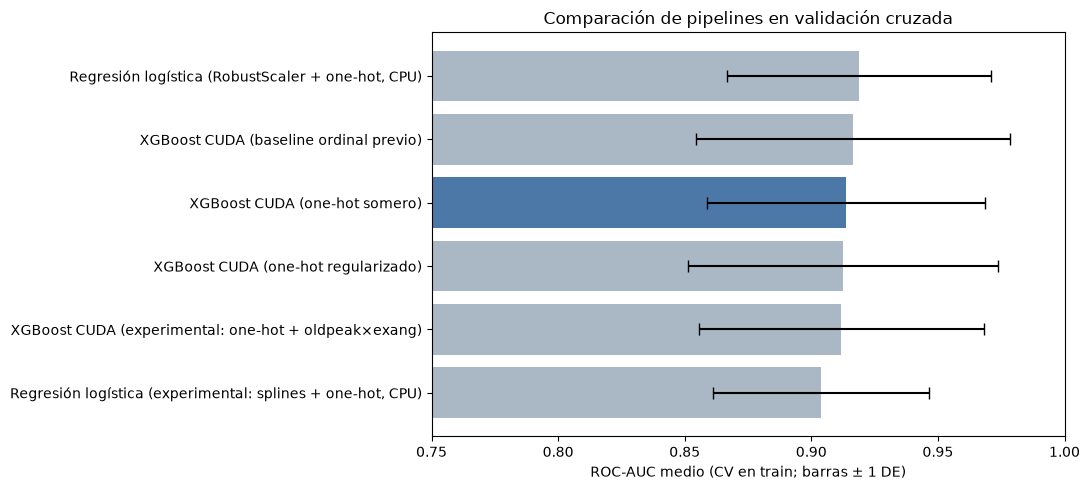

Modelo seleccionado por ROC-AUC CV: XGBoost CUDA (one-hot somero)
La elección es un baseline educativo; no implica que los controles de datos o clínicos estén completos.


In [7]:
comparison = result['comparison'].copy()
comparison.to_csv(TABLES_DIR / 'comparacion_modelos_validacion_cruzada.csv', index=False)
display(comparison.style.format({'roc_auc_cv_promedio': '{:.3f}', 'roc_auc_cv_desv': '{:.3f}'}))
cv_plot = comparison.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(cv_plot['modelo'], cv_plot['roc_auc_cv_promedio'],
        xerr=cv_plot['roc_auc_cv_desv'], capsize=4,
        color=['#4C78A8' if name == result['selected_name'] else '#AAB7C4'
               for name in cv_plot['modelo']])
ax.set_xlabel('ROC-AUC medio (CV en train; barras ± 1 DE)')
ax.set_xlim(0.75, 1.0)
ax.set_title('Comparación de pipelines en validación cruzada')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'comparacion_roc_auc_validacion_cruzada.png', dpi=180, bbox_inches='tight')
plt.show()
print('Modelo seleccionado por ROC-AUC CV:', result['selected_name'])
print('La elección es un baseline educativo; no implica que los controles de datos o clínicos estén completos.')

### Experimento: transformaciones de variables

El candidato XGBoost agrega sólo `oldpeak × exang`, calculado dentro del pipeline sin cambiar el contrato de entrada de 13 columnas. El candidato logístico reemplaza la relación lineal de cada variable continua por una base spline cuadrática con tres nudos cuantílicos; las variables categóricas conservan one-hot. La comparación es pareada fold a fold contra cada referencia correspondiente. Estas pruebas usan exclusivamente validación cruzada en train y no seleccionan el modelo final.

,delta_xgb_interaccion_oldpeak_exang,delta_logistica_splines
fold,,
1,+0.000,-0.027
2,-0.004,-0.028
3,-0.004,+0.006
4,-0.002,-0.018
5,+0.000,-0.008


Delta medio XGBoost interacción: -0.002
Delta medio logística splines: -0.015


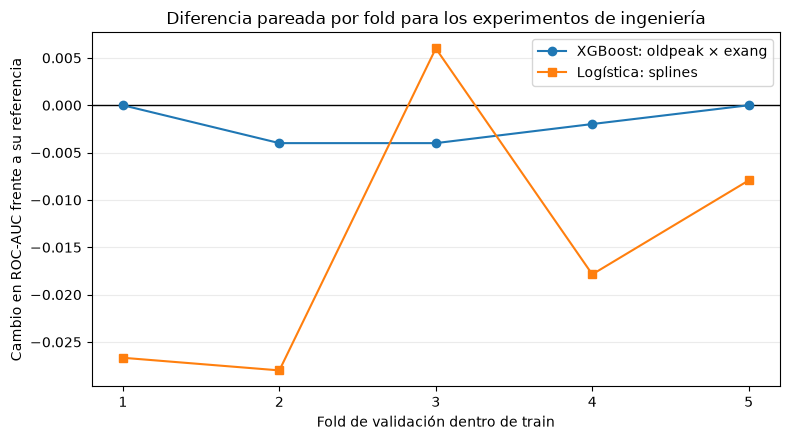

In [8]:
fold_scores = result['cv_fold_scores'].copy()
fold_scores.index.name = 'fold'
fold_scores.to_csv(TABLES_DIR / 'roc_auc_cv_por_fold.csv')
interaction_name = next(name for name in fold_scores.columns if 'oldpeak×exang' in name)
xgb_reference = 'XGBoost CUDA (one-hot somero)'
spline_name = next(name for name in fold_scores.columns if 'experimental: splines' in name)
logistic_reference = 'Regresión logística (RobustScaler + one-hot, CPU)'
deltas = pd.DataFrame({
    'delta_xgb_interaccion_oldpeak_exang': fold_scores[interaction_name] - fold_scores[xgb_reference],
    'delta_logistica_splines': fold_scores[spline_name] - fold_scores[logistic_reference],
})
deltas.to_csv(TABLES_DIR / 'feature_engineering_delta_auc_por_fold.csv')
display(deltas.style.format('{:+.3f}'))
print('Delta medio XGBoost interacción:', f"{deltas.iloc[:, 0].mean():+.3f}")
print('Delta medio logística splines:', f"{deltas.iloc[:, 1].mean():+.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
fold_numbers = deltas.index.to_numpy()
ax.axhline(0, color='black', linewidth=1)
ax.plot(fold_numbers, deltas.iloc[:, 0], marker='o', label='XGBoost: oldpeak × exang')
ax.plot(fold_numbers, deltas.iloc[:, 1], marker='s', label='Logística: splines')
ax.set_xticks(fold_numbers)
ax.set_xlabel('Fold de validación dentro de train')
ax.set_ylabel('Cambio en ROC-AUC frente a su referencia')
ax.set_title('Diferencia pareada por fold para los experimentos de ingeniería')
ax.legend()
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'feature_engineering_delta_auc_por_fold.png', dpi=180, bbox_inches='tight')
plt.show()

### Comprobación de estabilidad con validación cruzada repetida

Para reducir la dependencia de una sola partición de folds, repetimos cinco folds estratificados diez veces dentro del conjunto de entrenamiento. En cada repetición se comparan los mismos folds para cada candidato y su referencia. Las repeticiones se solapan en observaciones y no son 50 muestras independientes; usamos el resultado para evaluar estabilidad, no para afirmar significación estadística. El conjunto test no interviene en esta comparación.

,experimento,roc_auc_referencia,roc_auc_candidato,delta_medio,delta_mediano_por_repeticion,delta_min_por_repeticion,delta_max_por_repeticion,repeticiones_mejora,repeticiones_empate,repeticiones_empeora
0,XGBoost interacción oldpeak × exang,0.913,0.913,+0.0002,-0.0008,-0.0023,+0.0055,4,0,6
1,Logística splines,0.919,0.901,-0.0180,-0.0197,-0.0261,-0.0067,0,0,10


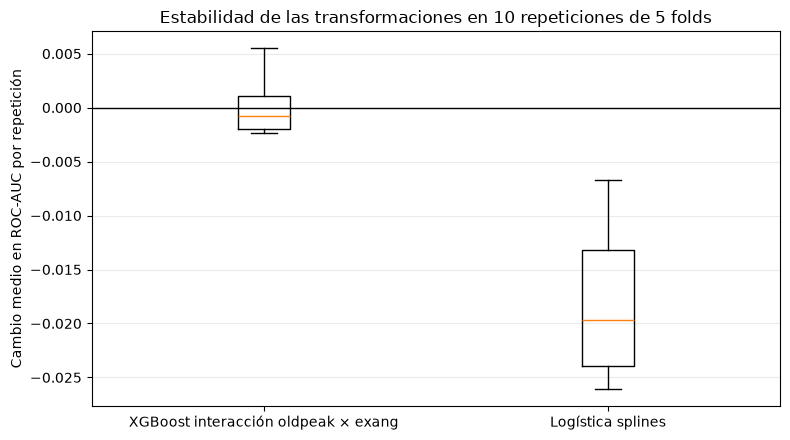

In [9]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from src.modeling import build_candidates

repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
candidate_pipelines = build_candidates()
repeated_pairs = [
    ('XGBoost interacción oldpeak × exang',
     'XGBoost CUDA (one-hot somero)',
     'XGBoost CUDA (experimental: one-hot + oldpeak×exang)'),
    ('Logística splines',
     'Regresión logística (RobustScaler + one-hot, CPU)',
     'Regresión logística (experimental: splines + one-hot, CPU)'),
]
summary_rows, repeat_rows = [], []
for label, reference, candidate in repeated_pairs:
    reference_scores = cross_val_score(
        candidate_pipelines[reference], result['X_train'], result['y_train'],
        cv=repeated_cv, scoring='roc_auc', n_jobs=None)
    candidate_scores = cross_val_score(
        candidate_pipelines[candidate], result['X_train'], result['y_train'],
        cv=repeated_cv, scoring='roc_auc', n_jobs=None)
    fold_deltas = (candidate_scores - reference_scores).reshape(10, 5)
    repeat_means = fold_deltas.mean(axis=1)
    summary_rows.append({
        'experimento': label,
        'roc_auc_referencia': reference_scores.mean(),
        'roc_auc_candidato': candidate_scores.mean(),
        'delta_medio': (candidate_scores - reference_scores).mean(),
        'delta_mediano_por_repeticion': np.median(repeat_means),
        'delta_min_por_repeticion': repeat_means.min(),
        'delta_max_por_repeticion': repeat_means.max(),
        'repeticiones_mejora': int((repeat_means > 0).sum()),
        'repeticiones_empate': int((repeat_means == 0).sum()),
        'repeticiones_empeora': int((repeat_means < 0).sum()),
    })
    repeat_rows.extend({'experimento': label, 'repeticion': i + 1,
                        'delta_roc_auc': float(delta)}
                       for i, delta in enumerate(repeat_means))

repeated_summary = pd.DataFrame(summary_rows)
repeated_deltas = pd.DataFrame(repeat_rows)
repeated_summary.to_csv(TABLES_DIR / 'feature_engineering_repeated_cv.csv', index=False)
repeated_deltas.to_csv(TABLES_DIR / 'feature_engineering_repeated_cv_por_repeticion.csv', index=False)
display(repeated_summary.style.format({
    'roc_auc_referencia': '{:.3f}', 'roc_auc_candidato': '{:.3f}',
    'delta_medio': '{:+.4f}', 'delta_mediano_por_repeticion': '{:+.4f}',
    'delta_min_por_repeticion': '{:+.4f}', 'delta_max_por_repeticion': '{:+.4f}',
}))

fig, ax = plt.subplots(figsize=(8, 4.5))
box_data = [repeated_deltas.loc[repeated_deltas['experimento'].eq(label), 'delta_roc_auc']
            for label, _, _ in repeated_pairs]
ax.boxplot(box_data, tick_labels=[label for label, _, _ in repeated_pairs], showfliers=True)
ax.axhline(0, color='black', linewidth=1)
ax.set_ylabel('Cambio medio en ROC-AUC por repetición')
ax.set_title('Estabilidad de las transformaciones en 10 repeticiones de 5 folds')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'feature_engineering_repeated_cv.png', dpi=180, bbox_inches='tight')
plt.show()

#### Decisión de implementación

No se incorporan estas transformaciones al pipeline final. La interacción explícita aporta una diferencia media prácticamente nula y no es consistente; el XGBoost de profundidad 2 ya puede aprender interacciones simples mediante divisiones sucesivas. Las splines amplían los grados de libertad de la logística con sólo 226 filas de entrenamiento y empeoran en las diez repeticiones. Añadir complejidad sin mejora reproducible puede ajustar ruido o peculiaridades de esta muestra y eleva el costo de mantenimiento. Este resultado descarta estos candidatos con la evidencia actual; no demuestra que toda ingeniería de variables sea inútil.

## 7. Evaluación final en test

Se comparan las métricas de los dos pipelines sobre los mismos 76 registros retenidos. Accuracy depende de las clases asignadas al umbral predeterminado; ROC-AUC evalúa el ordenamiento de los scores a través de umbrales. Las matrices y curvas siguientes permiten ver qué errores explican el resultado. No tienen interpretación clínica demostrada.


### Cómo interpretar la comparación

La matriz de confusión separa verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos. Accuracy cuenta la fracción total acertada y puede cambiar por uno o pocos registros en una prueba pequeña. ROC-AUC, en cambio, evalúa la capacidad de ordenar las clases a través de umbrales y no equivale a accuracy.

La conclusión debe basarse en los conteos y en el conjunto de métricas, no sólo en qué barra de accuracy es mayor. Una diferencia de un caso no demuestra que un algoritmo sea intrínsecamente mejor; tampoco valida clínicamente el modelo.

,Pipeline previo (ordinal),Pipeline nuevo (one-hot)
accuracy,0.789,0.776
precision_clase_1,0.791,0.786
recall_clase_1,0.829,0.805
f1_clase_1,0.810,0.795
roc_auc,0.875,0.875


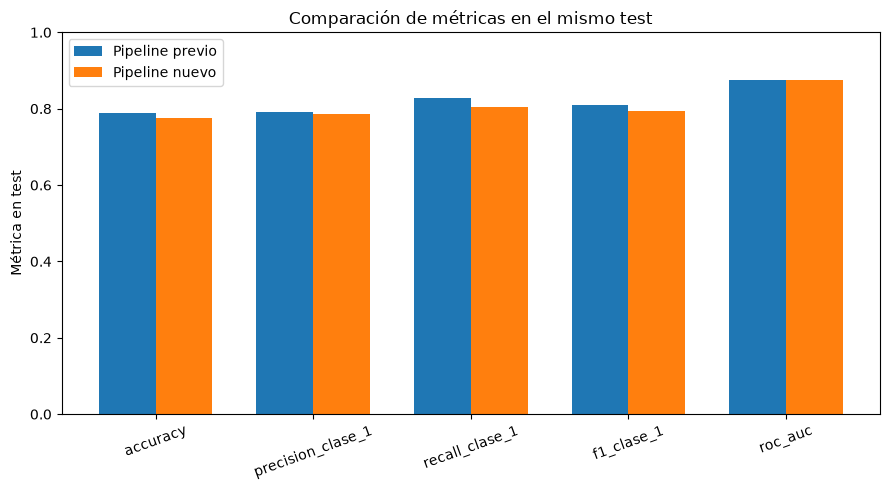

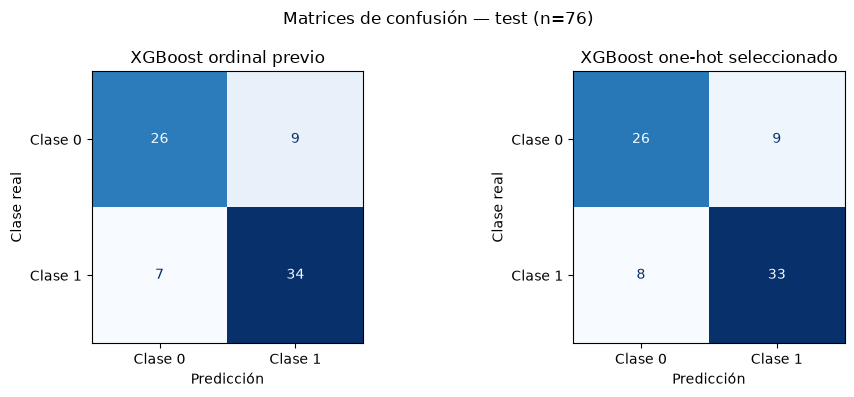

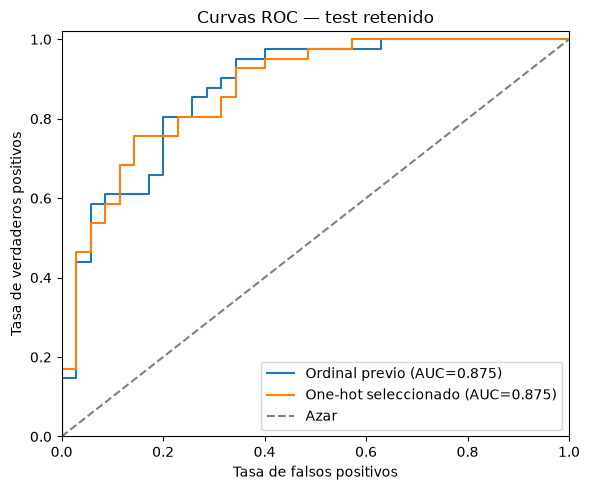

El baseline acertó 60/76 y el one-hot 59/76; diferencia: 1 caso(s).
Compare matrices: si las diferencias son de uno o pocos casos, accuracy no respalda por sí sola una superioridad estable. En estos resultados, el ROC-AUC es igual para ambos pipelines.
No existe umbral clínico validado ni garantía de sensibilidad adecuada para uso sanitario.


In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve, roc_auc_score

metrics = pd.DataFrame({
    'Pipeline previo (ordinal)': result['baseline_metrics'],
    'Pipeline nuevo (one-hot)': result['metrics'],
})
metrics.to_csv(TABLES_DIR / 'comparacion_metricas_test_antes_despues.csv')
display(metrics.style.format('{:.3f}'))

# Comparación de métricas agregadas.
fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(metrics.index))
width = 0.36
ax.bar(positions - width/2, metrics.iloc[:, 0], width, label='Pipeline previo')
ax.bar(positions + width/2, metrics.iloc[:, 1], width, label='Pipeline nuevo')
ax.set_xticks(positions, metrics.index, rotation=20)
ax.set_ylim(0, 1)
ax.set_ylabel('Métrica en test')
ax.set_title('Comparación de métricas en el mismo test')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'comparacion_metricas_test_antes_despues.png', dpi=180, bbox_inches='tight')
plt.show()

# Conteos de aciertos y errores, con filas=clase real y columnas=predicción.
labels = [0, 1]
baseline_cm = confusion_matrix(result['y_test'], result['baseline_predictions'], labels=labels)
onehot_cm = confusion_matrix(result['y_test'], result['predictions'], labels=labels)
cm_rows = []
for model_name, matrix in [('Pipeline previo (ordinal)', baseline_cm), ('Pipeline nuevo (one-hot)', onehot_cm)]:
    for i, actual in enumerate(labels):
        for j, predicted in enumerate(labels):
            cm_rows.append({'modelo': model_name, 'clase_real': actual, 'prediccion': predicted, 'conteo': int(matrix[i, j])})
pd.DataFrame(cm_rows).to_csv(TABLES_DIR / 'matrices_confusion_test.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, matrix, title in zip(axes, [baseline_cm, onehot_cm], ['XGBoost ordinal previo', 'XGBoost one-hot seleccionado']):
    ConfusionMatrixDisplay(matrix, display_labels=['Clase 0', 'Clase 1']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(title)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Clase real')
fig.suptitle("Matrices de confusión — test (n=76)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'matrices_confusion_test_comparacion.png', dpi=180, bbox_inches='tight')
plt.show()

# Curvas ROC de los scores en los mismos registros.
fig, ax = plt.subplots(figsize=(6, 5))
for scores, name in [(result['baseline_probabilities'], 'Ordinal previo'), (result['probabilities'], 'One-hot seleccionado')]:
    fpr, tpr, _ = roc_curve(result['y_test'], scores)
    auc = roc_auc_score(result['y_test'], scores)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Azar')
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos', title='Curvas ROC — test retenido')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'curvas_roc_test_comparacion.png', dpi=180, bbox_inches='tight')
plt.show()

baseline_correct = int(np.trace(baseline_cm))
onehot_correct = int(np.trace(onehot_cm))
print(f'El baseline acertó {baseline_correct}/76 y el one-hot {onehot_correct}/76; diferencia: {baseline_correct-onehot_correct} caso(s).')
print('Compare matrices: si las diferencias son de uno o pocos casos, accuracy no respalda por sí sola una superioridad estable. En estos resultados, el ROC-AUC es igual para ambos pipelines.')
print('No existe umbral clínico validado ni garantía de sensibilidad adecuada para uso sanitario.')

## 8. Explicabilidad del XGBoost seleccionado con SHAP

Se calculan atribuciones TreeSHAP exactas del modelo XGBoost, agrupando de nuevo las columnas one-hot por variable original. El resumen global usa los 302 registros únicos y ordena por media de contribución absoluta al margen log-odds. Los gráficos de dirección separan categorías nominales y variables cuantitativas; las categorías no se interpretan como una escala.

Para los casos de prueba, se muestran falsos negativos/falsos positivos y sus principales contribuciones hacia la clase codificada como 1 o 0. SHAP explica la salida del modelo en estos registros; no indica causalidad, riesgo clínico, ni prueba que una variable sea clínicamente importante. El score de clase 1 sigue sin calibrar.

In [11]:
from src.explainability import generate_explainability_artifacts
shap_onehot = generate_explainability_artifacts(
    result['model'], result['unique_data'], result['X_test'],
    result['y_test'], result['predictions'], result['probabilities'],
    FIGURES_DIR, TABLES_DIR, model_label='XGBoost one-hot seleccionado'
)
shap_ordinal = generate_explainability_artifacts(
    result['baseline_model'], result['unique_data'], result['X_test'],
    result['y_test'], result['baseline_predictions'], result['baseline_probabilities'],
    FIGURES_DIR, TABLES_DIR, model_label='XGBoost ordinal (mayor accuracy test)', artifact_prefix='ordinal'
)
display(shap_onehot.style.format({'mean_abs_shap_log_odds': '{:.3f}', 'mean_signed_shap_log_odds': '{:.3f}'}))
display(shap_ordinal.style.format({'mean_abs_shap_log_odds': '{:.3f}', 'mean_signed_shap_log_odds': '{:.3f}'}))
print('SHAP describe contribuciones del modelo, no causalidad ni importancia clínica.')
from src.explainability import plot_shap_comparison
shap_comparison = plot_shap_comparison(shap_onehot, shap_ordinal, FIGURES_DIR, TABLES_DIR)
display(shap_comparison.style.format({'mean_abs_shap_log_odds_onehot': '{:.3f}', 'mean_abs_shap_log_odds_ordinal': '{:.3f}'}))


,variable,mean_abs_shap_log_odds,mean_signed_shap_log_odds
0,cp,0.971,-0.035
1,ca,0.855,0.058
2,thal,0.599,0.033
3,oldpeak,0.407,-0.049
4,sex,0.395,0.025
5,thalach,0.346,-0.028
6,slope,0.306,-0.014
7,chol,0.291,-0.022
8,age,0.272,0.000
9,restecg,0.237,0.012


,variable,mean_abs_shap_log_odds,mean_signed_shap_log_odds
0,cp,0.872,-0.015
1,ca,0.643,0.048
2,thal,0.479,0.036
3,oldpeak,0.362,-0.015
4,sex,0.248,-0.008
5,thalach,0.210,-0.005
6,slope,0.191,-0.016
7,age,0.190,0.009
8,exang,0.154,0.001
9,chol,0.142,-0.009


SHAP describe contribuciones del modelo, no causalidad ni importancia clínica.


,variable,mean_abs_shap_log_odds_onehot,mean_abs_shap_log_odds_ordinal,orden_promedio
0,cp,0.971,0.872,0.921659
1,ca,0.855,0.643,0.749324
2,thal,0.599,0.479,0.538763
3,oldpeak,0.407,0.362,0.384390
4,sex,0.395,0.248,0.321277
5,thalach,0.346,0.210,0.277539
6,slope,0.306,0.191,0.248445
7,age,0.272,0.190,0.230935
8,chol,0.291,0.142,0.216557
9,restecg,0.237,0.134,0.185235


## 9. Cinco predicciones con nuevos datos sintéticos

Las cinco entradas son ejemplos sintéticos dentro de rangos observados; no representan individuos. El score para clase 1 no está calibrado y no debe interpretarse como riesgo clínico.

In [12]:
SAMPLE_PATH = PROJECT_ROOT / 'data/samples/predicciones_ejemplo.csv'
new_data = pd.read_csv(SAMPLE_PATH)
assert new_data.shape == (5, len(FEATURES))
artifact_path = save_model(result['model'], MODEL_PATH)
print('Artefacto del pipeline:', artifact_path)
display(predict_batch(new_data, artifact_path))

Artefacto del pipeline: C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\outputs\models\heart_disease_pipeline.joblib


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,prediction_class,score_class_1_uncalibrated
0,52,1,0,125,212,0,1,168,0,1.0,1,0,2,1,0.801189
1,61,0,2,140,250,0,0,150,1,2.3,1,1,3,0,0.267867
2,45,1,1,130,233,0,1,179,0,0.4,2,0,2,1,0.978634
3,68,1,0,170,284,1,2,132,1,3.0,0,2,3,0,0.011948
4,57,0,3,120,354,0,1,163,0,0.6,2,0,2,1,0.975111


## 9. Automatización propuesta e implementada

**Propuesta:** procesar un CSV mediante un comando batch. El flujo valida las 13 columnas esperadas, su orden y los nulos; carga el pipeline fijado (entrenado en CUDA), genera la clase y un score y guarda un CSV con marca temporal. Reduce preparación manual y conserva una salida trazable. No reentrena ni publica un modelo automáticamente; una actualización requiere evaluación y aprobación explícitas.

El siguiente paso ejecuta la función automatizada sobre el lote de cinco ejemplos. El CLI equivalente se puede correr desde la raíz:

```powershell
python src/automatizacion_predicciones.py data/samples/predicciones_ejemplo.csv outputs/models/heart_disease_pipeline.joblib outputs/predicciones_ejemplo.csv
```

In [13]:
from src.modeling import predict_batch
from datetime import datetime, timezone
automation_output = predict_batch(new_data, artifact_path)
automation_output.insert(0, 'generated_at_utc', datetime.now(timezone.utc).isoformat(timespec='seconds'))
CSV_OUTPUT = PROJECT_ROOT / 'outputs/models/predicciones_ejemplo.csv'
automation_output.to_csv(CSV_OUTPUT, index=False)
print(f'Lote validado y procesado: {len(automation_output)} filas')
print(f'CSV generado: {CSV_OUTPUT}')
display(automation_output[['prediction_class', 'score_class_1_uncalibrated']])

Lote validado y procesado: 5 filas
CSV generado: C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\outputs\models\predicciones_ejemplo.csv


,prediction_class,score_class_1_uncalibrated
0,1,0.801189
1,0,0.267867
2,1,0.978634
3,0,0.011948
4,1,0.975111


## Reflexión grupal propuesta

Para este proyecto, el componente con mayor impacto en el éxito del negocio sería **la forma de comunicar los resultados**. El modelo produce una señal, pero sus métricas dependen de una muestra pequeña, duplicados y una semántica de etiqueta y representatividad aún por validar. La automatización aporta consistencia, aunque también puede propagar errores si opera sin controles. Comunicar qué significa la salida, qué evidencia la respalda y cuáles son sus límites ayuda a evitar que una clasificación educativa se interprete como diagnóstico. Esta respuesta queda como propuesta para revisión grupal.

## Cierre y límites

El flujo completa una demostración reproducible de carga, exploración, preparación, entrenamiento, selección, evaluación, inferencia y automatización. Antes de cualquier uso externo al ejercicio académico se debe verificar procedencia y semántica de `target`, calidad y representatividad del dato, calibración, desempeño por subgrupos, privacidad, seguridad y aceptación experta. El informe 3.2.2 describe una simulación de gestión; sus estados y pronósticos no son evidencia de que este modelo haya sido desplegado o aceptado.